In [1]:
# prerequisites
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.autograd import Variable
from torchvision.utils import save_image

from VAE import VAE

from matplotlib import colors
import matplotlib.pyplot as plt 

데이터 셋 로더

In [2]:
import os
import pandas as pd
from torch.utils.data import Dataset, DataLoader

class CSVDataset(Dataset):
    def __init__(self, directory, transform=None):
        self.directory = directory
        self.transform = transform

        numerical = lambda _: int(''.join(filter(str.isdigit, _)))
        self.file_names = []
        for set in os.listdir(directory):
            csv_files = sorted((f for f in os.listdir(os.path.join(directory, set)) if f.endswith('.csv')), key = numerical)
            self.file_names.extend(list(map(lambda _:os.path.join(set, _), csv_files)))
        
        # self.file_names = [os.path.join(set, f)
        #                    for set in os.listdir(directory)
        #                    for f in os.listdir(os.path.join(directory, set)) if f.endswith('.csv')]

    def __len__(self):
        return len(self.file_names)

    def __getitem__(self, idx):
        file_path = os.path.join(self.directory, self.file_names[idx])
        data = pd.read_csv(file_path, header=None, index_col=False).values
        data = data.astype('float32')
        
        if self.transform:
            data = self.transform(data)

        assert data.shape == (64, 32), f"Data shape mismatch: got {data.shape}, expected (64, 32)"

        return torch.tensor(data), 0

(학습용) 데이터 셋 로더 인스턴스 만들기

In [3]:
# Define transformations if any
transform = None

# Dataset directories
input_dir = './vae_input_mtruss'
train_directory = input_dir
test_directory = input_dir

# Create datasets
train_dataset = CSVDataset(directory=train_directory, transform=transform)
test_dataset = CSVDataset(directory=test_directory, transform=transform)

# Data Loader (Input Pipeline)
bs = 32
train_loader = DataLoader(dataset=train_dataset, batch_size=bs, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=bs, shuffle=False)

학습할 토폴로지 디렉토리

In [4]:
reconstructed_dir = './vae_output_mtruss/'
os.makedirs(reconstructed_dir, exist_ok=True)

모델 인스턴스

In [5]:
# build model
vae = VAE(x_dim=64*32, h_dim1= 512, h_dim2=256, z_dim=2)
if torch.cuda.is_available():
    vae.cuda()

vae

Loss 및 최적화 알고리즘

In [7]:
optimizer = optim.Adam(vae.parameters())
# return reconstruction error + KL divergence losses
def loss_function(recon_x, x, mu, log_var):
    BCE = F.binary_cross_entropy(recon_x, x.view(-1, 64*32), reduction='sum')
    KLD = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())
    return BCE + KLD

vae

In [8]:
def train(epoch):
    vae.train()
    train_loss = 0
    for batch_idx, (data, _) in enumerate(train_loader):
        data = data.cuda()
        optimizer.zero_grad()
        
        recon_batch, mu, log_var = vae(data)
        loss = loss_function(recon_batch, data, mu, log_var)
        
        loss.backward()
        train_loss += loss.item()
        optimizer.step()
        
        if batch_idx % 100 == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), loss.item() / len(data)))
    print('====> Epoch: {} Average loss: {:.4f}'.format(epoch, train_loss / len(train_loader.dataset)))

In [9]:
def test():
    vae.eval()
    test_loss= 0
    with torch.no_grad():
        for data, _ in test_loader:
            data = data.cuda()
            recon, mu, log_var = vae(data)
            
            # sum up batch loss
            test_loss += loss_function(recon, data, mu, log_var).item()
        
    test_loss /= len(test_loader.dataset)
    print('====> Test set loss: {:.4f}'.format(test_loss))

In [10]:
for epoch in range(1, 201):
    train(epoch)
    test()

Train Epoch: 1 [0/33 (0%)]	Loss: 1426.612549
====> Epoch: 1 Average loss: 1425.0406
====> Test set loss: 1309.3424
Train Epoch: 2 [0/33 (0%)]	Loss: 1315.863037
====> Epoch: 2 Average loss: 1311.4845
====> Test set loss: 1048.5145
Train Epoch: 3 [0/33 (0%)]	Loss: 1047.776367
====> Epoch: 3 Average loss: 1048.8258
====> Test set loss: 1055.8009
Train Epoch: 4 [0/33 (0%)]	Loss: 1062.194214
====> Epoch: 4 Average loss: 1054.2053
====> Test set loss: 844.4054
Train Epoch: 5 [0/33 (0%)]	Loss: 840.566162
====> Epoch: 5 Average loss: 843.1326
====> Test set loss: 813.9516
Train Epoch: 6 [0/33 (0%)]	Loss: 813.497498
====> Epoch: 6 Average loss: 813.2636
====> Test set loss: 822.0775
Train Epoch: 7 [0/33 (0%)]	Loss: 819.382202
====> Epoch: 7 Average loss: 818.1046
====> Test set loss: 805.9618
Train Epoch: 8 [0/33 (0%)]	Loss: 800.982727
====> Epoch: 8 Average loss: 800.8310
====> Test set loss: 784.3621
Train Epoch: 9 [0/33 (0%)]	Loss: 780.073242
====> Epoch: 9 Average loss: 782.5783
====> Test 

In [11]:
with torch.no_grad():
    z = torch.randn(64, 2).cuda()
    sample = vae.decoder(z).cuda()
    
    save_image(sample.view(64, 1, 64, 32), os.path.join(reconstructed_dir, 'sample') + '.png')

In [12]:
# Create a grid of evenly spaced points around (0, 0)
n_points = 8  # Number of points along one dimension
grid_x = torch.linspace(-0.5, 0.5, n_points)
grid_y = torch.linspace(-0.5, 0.5, n_points)
grid = torch.cartesian_prod(grid_x, grid_y).cuda()

# Ensure the grid has the correct shape (64, 2)
z = grid.view(-1, 2)

with torch.no_grad():
    sample = vae.decoder(z).cuda()
    
    save_image(sample.view(64, 1, 64, 32), os.path.join(reconstructed_dir, 'sample_') + '.png')

In [13]:
input_loader = DataLoader(dataset=train_dataset, batch_size=1, shuffle=False)

66


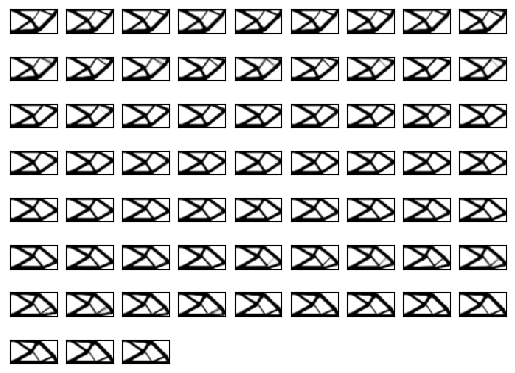

In [14]:
with torch.no_grad():
    latents = []
    for batch_idx, (data, _) in enumerate(input_loader):
        # Move data to GPU if available
        data = data.cuda()
        restored, latent, _ = vae.forward(data)
        latents.append(latent)

        pd.DataFrame(data.cpu().view(64, 32)).to_csv(f'{reconstructed_dir}/{batch_idx}_data.csv', index=False, header=False)
        pd.DataFrame(restored.cpu().view(64, 32)).to_csv(f'{reconstructed_dir}/{batch_idx}_rest.csv', index=False, header=False)


        # save_image(data.view(1, 1, 64, 32), f'./vae_output/{batch_idx}_data' + '.png')
        # save_image(restored.view(1, 1, 64, 32), f'./vae_output/{batch_idx}_restored' + '.png')

from csv2fig import csv2fig
csv2fig(reconstructed_dir, reconstructed_dir, False)

In [15]:
latents

[tensor([[-1.2261,  2.3000]], device='cuda:0'),
 tensor([[-1.2320,  2.2968]], device='cuda:0'),
 tensor([[-1.3344,  2.1886]], device='cuda:0'),
 tensor([[-1.4768,  1.9648]], device='cuda:0'),
 tensor([[-2.0487,  1.1176]], device='cuda:0'),
 tensor([[-2.3120,  0.5212]], device='cuda:0'),
 tensor([[-2.3850, -0.2565]], device='cuda:0'),
 tensor([[-2.2984, -0.8473]], device='cuda:0'),
 tensor([[-2.4865, -1.1967]], device='cuda:0'),
 tensor([[-2.4116, -1.8187]], device='cuda:0'),
 tensor([[-2.1969, -2.3580]], device='cuda:0'),
 tensor([[-1.8842, -2.8010]], device='cuda:0'),
 tensor([[-1.4236, -3.0468]], device='cuda:0'),
 tensor([[-1.0157, -3.2736]], device='cuda:0'),
 tensor([[-0.5103, -3.4175]], device='cuda:0'),
 tensor([[-0.0147, -3.4821]], device='cuda:0'),
 tensor([[ 0.4947, -3.4851]], device='cuda:0'),
 tensor([[ 0.9997, -3.3183]], device='cuda:0'),
 tensor([[ 1.4566, -3.1303]], device='cuda:0'),
 tensor([[ 1.8943, -2.8664]], device='cuda:0'),
 tensor([[ 2.2255, -2.5700]], device='cu

2112 ~ 2144 -> latent space 맵핑

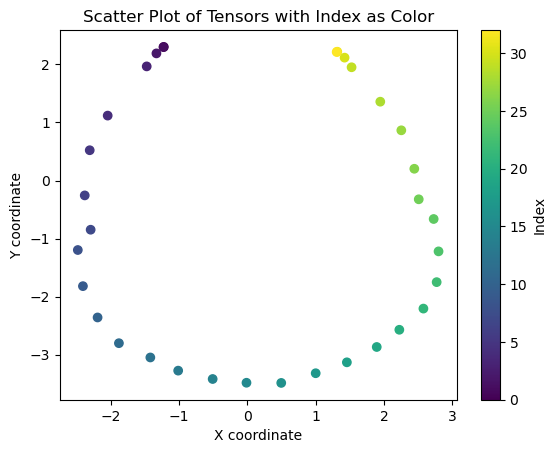

In [16]:
# Extract x and y coordinates from the tensors
x_coords = [tensor[0][0].item() for tensor in latents]
y_coords = [tensor[0][1].item() for tensor in latents]

# Scatter plot with index as color
plt.scatter(x_coords, y_coords, c=range(len(latents)), cmap='viridis')
plt.colorbar(label='Index')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.title('Scatter Plot of Tensors with Index as Color')
plt.show()

In [17]:
# torch.save(vae.state_dict(), './vae_model_mtruss.pt')

In [18]:
load_model = VAE(x_dim=64*32, h_dim1= 512, h_dim2=256, z_dim=2)
load_model.load_state_dict(torch.load('./vae_model_mtruss.pt'))

C:\Users\User\AppData\Local\Temp\ipykernel_4600\3859169236.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  load_model.load_state_dict(torch.load('./vae_model_mtruss.pt')

<All keys matched successfully>

In [22]:
from FEA_Comp import fea_c
from bc_options import *

with torch.no_grad():
    z = torch.randn(1, 2)
    sample = load_model.decoder(z).cuda()
    
    z_ = torch.randn(1, 2)
    sample_ = load_model.decoder(z_).cuda()

n1 = pd.DataFrame(sample.cpu().view(64, 32)).to_numpy()
n2 = pd.DataFrame(sample_.cpu().view(64, 32)).to_numpy()

fea_c(64, 32, MTruss, 0, 2112, n1), fea_c(64, 32, MTruss, 0, 2112, n2)

(26988323.68405306, 4382798472.852614)

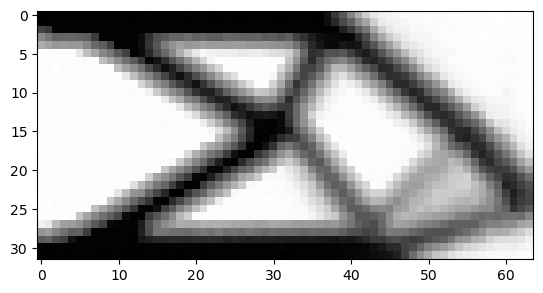

In [23]:
_,ax = plt.subplots()
ax.imshow(-n1.reshape((64,32)).T, cmap='gray', interpolation='none', norm=colors.Normalize(vmin=-1,vmax=0))
plt.show()

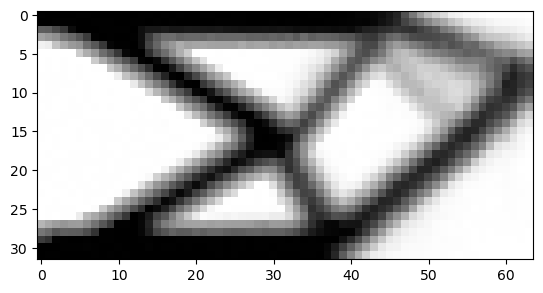

In [19]:
_,ax = plt.subplots()
ax.imshow(-n2.reshape((64,32)).T, cmap='gray', interpolation='none', norm=colors.Normalize(vmin=-1,vmax=0))
plt.show()

In [20]:
z, z_

(tensor([[0.6967, 0.2826]]), tensor([[0.5584, 0.7345]]))

이제 뭘 할거냐: 만들어진 2차원 평면에 대해서 컴플라이언스 히트맵을 그릴 겁니다.

100%|██████████| 10000/10000 [12:33<00:00, 13.27it/s]


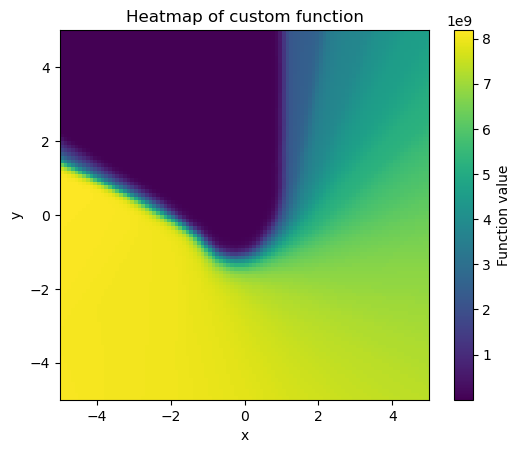

In [27]:
# from FEA_Comp import fea_c
# from bc_options import *
from tqdm import tqdm

# 이차원 벡터 z 를 받으면 그에 대한 토폴로지를 복원해서 컴플라이언스를 계산:
def compliance_per_z(z):
    with torch.no_grad():
        sample = load_model.decoder(z).cuda()               # z 에서 토폴로지 복원
    n = pd.DataFrame(sample.cpu().view(64,32)).to_numpy()   # (모양 고치고 타입 변환)
    return fea_c(64, 32, MTruss, 0, 2112, n)                # 컴플라이언스 계산

# 평면을 정의합니다. 어디가 좋을까요?
# 일단은 원점 위의 10*10 사각형에 대한 100*100 샘플링.

# 우선 x, y 구간을 정한다
x = torch.linspace(-5, 5, steps=100)  # 100 points from -5 to 5 on the x-axis
y = torch.linspace(-5, 5, steps=100)  # 100 points from -5 to 5 on the y-axis

# 그 다음엔 메쉬그리드를 만든다. (샘플링될 점들)
xx, yy = torch.meshgrid(x, y)        # 도대체 왜 이런게 있는 걸까.
xx, yy = xx.flatten(), yy.flatten()  # Flatten to iterate over each point

# 값을 반환 받을 영역을 만든다
values = torch.zeros_like(xx)

# 이제 함수를 돌린다:
for idx in tqdm(range(xx.shape[0])):
    xy_tensor = torch.tensor([[xx[idx], yy[idx]]])  # 1x2 tensor for each point
    values[idx] = compliance_per_z(xy_tensor)  # Pass to the function and store result

# 함수로 나온 결과의 모양을 고친다.
values = values.view(100, 100)

# 이제 그림을 그리기 위해 torch 변수에서 numpy 숫자 배열만 빼온다.
values_np = values.numpy()

# 나머지 어쩌고
plt.imshow(values_np, extent=[x.min(), x.max(), y.min(), y.max()], origin='lower', cmap='viridis')
plt.colorbar(label='Function value')
plt.title('Heatmap of custom function')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

In [53]:
values_np.min(), values_np.max()

(112.4433, 8186574000.0)

이거 matplotlib 보다 매트랩이 나을 듯...

In [ ]:
# show hight map in 3d
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(x, y, values_np, cmap='viridis')
plt.title('z as 3d height map')
plt.show()

2112 대신 2144 라면?

100%|██████████| 10000/10000 [12:31<00:00, 13.31it/s]


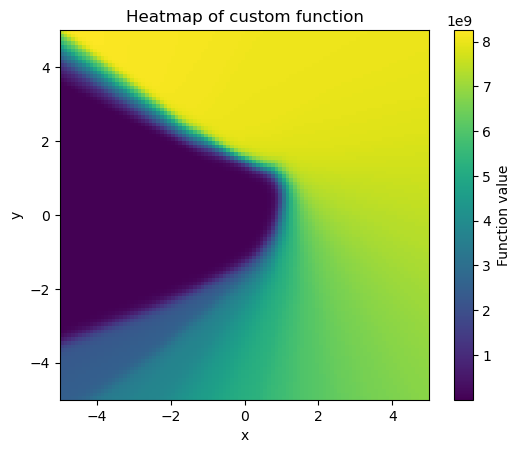

In [46]:
def compliance_per_z_(z):
    with torch.no_grad():
        sample = load_model.decoder(z).cuda()               # z 에서 토폴로지 복원
    n = pd.DataFrame(sample.cpu().view(64,32)).to_numpy()   # (모양 고치고 타입 변환)
    return fea_c(64, 32, MTruss, 0, 2144, n)                # 컴플라이언스 계산

x = torch.linspace(-5, 5, steps=100)  # 100 points from -5 to 5 on the x-axis
y = torch.linspace(-5, 5, steps=100)  # 100 points from -5 to 5 on the y-axis

xx, yy = torch.meshgrid(x, y)        # 도대체 왜 이런게 있는 걸까.
xx, yy = xx.flatten(), yy.flatten()  # Flatten to iterate over each point

values_ = torch.zeros_like(xx)

# 이제 함수를 돌린다:
for idx in tqdm(range(xx.shape[0])):
    xy_tensor = torch.tensor([[xx[idx], yy[idx]]])  # 1x2 tensor for each point
    values_[idx] = compliance_per_z_(xy_tensor)  # Pass to the function and store result

# 함수로 나온 결과의 모양을 고친다.
values_ = values_.view(100, 100)

# 이제 그림을 그리기 위해 torch 변수에서 numpy 숫자 배열만 빼온다.
values_np_ = values_.numpy()

# 나머지 어쩌고
plt.imshow(values_np_, extent=[x.min(), x.max(), y.min(), y.max()], origin='lower', cmap='viridis')
plt.colorbar(label='Function value')
plt.title('Heatmap of custom function')
plt.xlabel('x')
plt.ylabel('y')
plt.show()       